In [8]:
import re
import numpy as np
import pandas as pd
from transformers import pipeline
import matplotlib.pyplot as plt

In [3]:
statements = pd.read_parquet("data/statements.parquet")
clf = pipeline("text-classification", model="ProsusAI/finbert", top_k=None, device="mps")

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 9818.15it/s]


In [4]:
def split_sentences(text):
    parts = re.split(r"(?<=[.!?])\s+(?=[A-Z\"“(])|\n+", text)
    return [p.strip() for p in parts if p and len(p.strip()) >= 20]

rows = []
for i, st in statements.iterrows():
    for j, sent in enumerate(split_sentences(st["text"])):
        rows.append({"stmt_id": i, "bank": st["bank"], "date": st["date"], "sent_id": j, "sentence": sent})

sents = pd.DataFrame(rows)
print(len(sents))
sents.groupby("bank").size()

10928


bank
ECB     8908
FOMC    2020
dtype: int64

In [5]:
out = clf(sents["sentence"].tolist(), batch_size=32, truncation=True)
probs = pd.DataFrame([{d["label"]: d["score"] for d in o} for o in out])

sents = pd.concat([sents, probs], axis=1)
sents["tone"] = sents["positive"] - sents["negative"]
sents.to_parquet("data/finbert_sentences.parquet")

In [6]:
pd.set_option("display.max_colwidth", 200)
cols = ["bank", "date", "tone", "sentence"]
display(sents.nlargest(5, "tone")[cols])
display(sents.nsmallest(5, "tone")[cols])
sents.groupby("bank")[["positive", "negative", "neutral"]].mean().round(2)

,bank,date,tone,sentence
4815,ECB,2015-04-15,0.944333,Loan dynamics also gradually improved further.
4962,ECB,2015-07-16,0.943721,Loan dynamics continued to improve.
5044,ECB,2015-09-03,0.943721,Loan dynamics continued to improve.
5112,ECB,2015-10-22,0.943721,Loan dynamics continued to improve.
3004,ECB,2013-02-07,0.943457,"In particular, banks reported improvements across all funding categories in the fourth quarter."


,bank,date,tone,sentence
2445,ECB,2012-06-06,-0.968952,"The annual growth rate of M3 fell to 2.5% in April, down from 3.1% in March, following strong inflows into money in the first quarter of the year."
10005,ECB,2023-09-14,-0.968782,"Amid weak lending and the reduction in the Eurosystem balance sheet, the annual growth rate of M3 fell from 0.6 per cent in June to an all-time low of -0.4 per cent in July."
2838,ECB,2012-12-06,-0.968608,"According to Eurostat’s flash estimate, euro area annual HICP inflation fell to 2.2% in November 2012, down from 2.5% in October and from 2.6% in the two previous months."
9905,ECB,2023-07-27,-0.968484,"Energy prices fell again, dropping by 5.6 per cent, year on year."
3317,ECB,2013-07-04,-0.968461,"Real GDP declined by 0.3% in the first quarter of 2013, following a contraction of 0.6% in the last quarter of 2012."


,positive,negative,neutral
bank,,,
ECB,0.48,0.24,0.29
FOMC,0.38,0.25,0.37


In [7]:
infl = sents[sents["sentence"].str.contains(r"\binflation\b", case=False)].copy()
up   = infl["sentence"].str.contains(r"\b(?:rose|increased|picked up|higher|accelerat\w*|rising)\b", case=False)
down = infl["sentence"].str.contains(r"\b(?:fell|declined|decreased|eased|lower|falling)\b", case=False)

print("inflation UP  :", round(infl.loc[up & ~down, "tone"].mean(), 3), "n =", (up & ~down).sum())
print("inflation DOWN:", round(infl.loc[down & ~up, "tone"].mean(), 3), "n =", (down & ~up).sum())
display(infl.loc[up & ~down].sample(5, random_state=0)[cols])

inflation UP  : 0.357 n = 216
inflation DOWN: -0.398 n = 175


,bank,date,tone,sentence
10593,ECB,2024-07-18,0.819392,"Wages are still rising at an elevated rate, making up for the past period of high inflation."
5107,ECB,2015-10-22,0.925459,"Inflation rates are foreseen to pick up further during 2016 and 2017, supported by the expected economic recovery, the pass-through of past declines in the euro exchange rate and the assumption of..."
7377,ECB,2020-01-23,0.928223,"Euro area annual HICP inflation increased to 1.3% in December 2019, from 1.0% in November, reflecting mainly higher energy price inflation."
9621,ECB,2023-03-16,-0.369729,"Services inflation, which rose to 4.8 per cent in February, is also still being driven by the gradual pass-through of past energy cost increases, pent-up demand from the reopening of the economy a..."
9341,ECB,2022-10-27,0.933606,"Inflation rose to 9.9 per cent in September, reflecting further increases in all components."


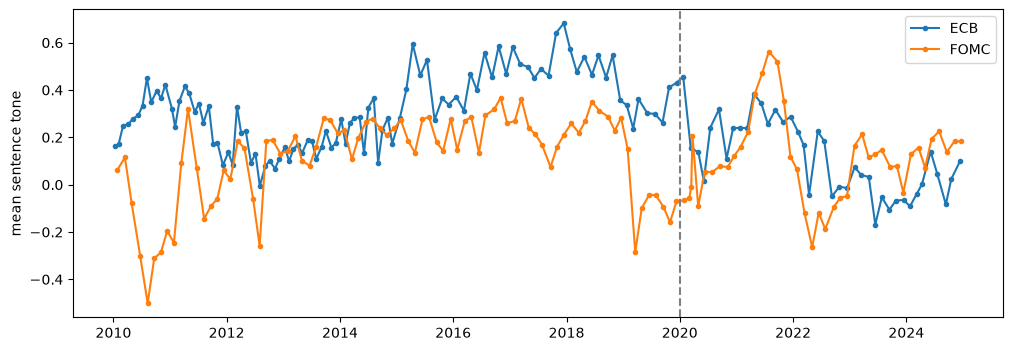

,count,mean,std,min,25%,50%,75%,max
bank,,,,,,,,
ECB,139.0,-0.000,0.105,-0.302,-0.072,0.007,0.065,0.268
FOMC,121.0,0.001,0.125,-0.436,-0.059,0.011,0.064,0.443


In [9]:
TRAIN_END = pd.Timestamp("2019-12-31")

stmt = (sents.groupby(["stmt_id", "bank", "date"])["tone"].mean()
        .reset_index().sort_values(["bank", "date"]).reset_index(drop=True))
stmt["d_tone"] = stmt.groupby("bank")["tone"].diff()

# standardize Δtone per bank using TRAIN statistics only
train = stmt["date"] <= TRAIN_END
mu = stmt[train].groupby("bank")["d_tone"].mean()
sd = stmt[train].groupby("bank")["d_tone"].std()
stmt["z_d_tone"] = (stmt["d_tone"] - stmt["bank"].map(mu)) / stmt["bank"].map(sd)

fig, ax = plt.subplots(figsize=(12, 4))
for b, g in stmt.groupby("bank"):
    ax.plot(g["date"], g["tone"], marker=".", label=b)
ax.axvline(TRAIN_END, color="gray", linestyle="--")
ax.set_ylabel("mean sentence tone")
ax.legend()
plt.show()

stmt.groupby("bank")["d_tone"].describe().round(3)